This is the model 

In [99]:
# Import stuff
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pickle
import torch 
import torch.nn as nn

import matplotlib.pyplot as plt
import torchvision
import numpy as np
from model_class import MyModel



In [100]:
def normalize_features(x):
    mean = torch.mean (x, dim=0)
    std  = torch.std(x, dim = 0)
    return (x-mean)/std

In [101]:
# Load data and create datasets
data = pd.read_csv("data/hand_gestures.csv")

# Separate features (landmarks) and labels
x_df = data.drop("label", axis=1)
y_df = data["label"]

#Convert from dataframes to tensors
x = torch.tensor(x_df.values).to(torch.float32)
y = torch.tensor(y_df.values) - 1 # cause we expect labels to start from 0

#Normalize the data

x = normalize_features(x)

# Split into train/test sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)






C:\Users\kalli\AppData\Local\Temp\ipykernel_35864\2527225718.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


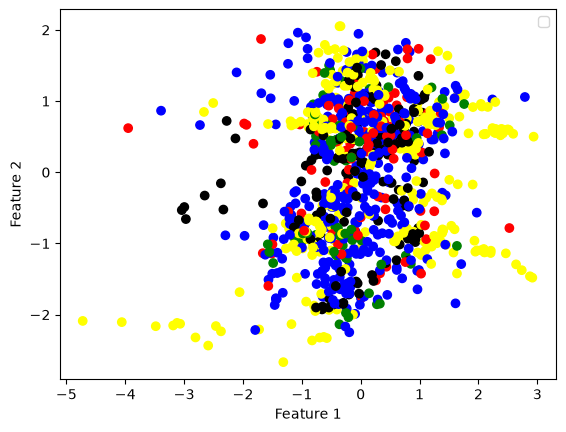

In [102]:
#Visualize data
colors = np.array(["red", "blue", "yellow", "black", "green"])
y_colors = y_train.detach().numpy() 


plt.scatter(x_train[:, 11], x_train[:,12], c = colors[y_colors])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()



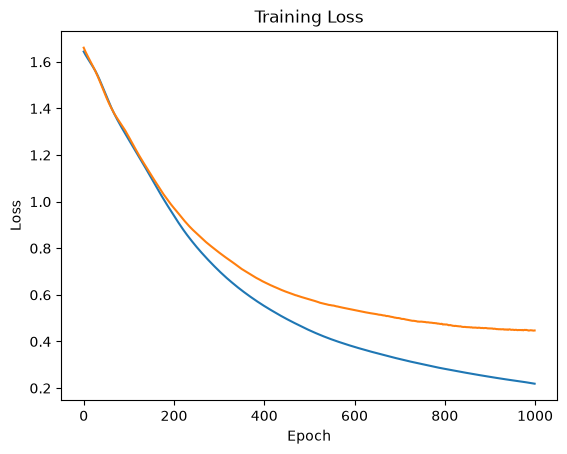

In [106]:
# Create and train the model

epochs = 1000

model = MyModel()
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

losses_train = []
losses_test = []

for epoch in range (epochs):

    y_pred = model(x_train)

    loss = loss_fn(y_pred, y_train)

    y_pred_test = model(x_test)
    loss_test = loss_fn(y_pred_test, y_test)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()
    losses_train.append(loss.item())
    losses_test.append(loss_test.item())

plt.plot(range(epochs), losses_train)
plt.plot(range(epochs), losses_test)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()
    



In [85]:
# Evaluate model

In [107]:
# Save the model
with open("data/model.pkl", "wb") as f:
    torch.save(model.state_dict(), f)
print("Model saved to data/model.pkl")

Model saved to data/model.pkl
